In [1]:

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive5')

PROJECT = Path("/content/drive5/MyDrive/Ocular_Project")
RESULTS = PROJECT / "results/IITD"
OUT_DIR = RESULTS / "notebook14_visualization_ablation"
OUT_DIR.mkdir(parents=True, exist_ok=True)

assert PROJECT.exists(), f"Project folder not found: {PROJECT}"

print("Notebook 14 setup verified")
print("Project:", PROJECT)
print("Output:", OUT_DIR)

for folder in [
    "notebook10_recognition_augmented",
    "notebook11_gan_vs_diffusion",
    "notebook12_membership_inference",
]:
    path = RESULTS / folder
    print(f"{'FOUND' if path.exists() else 'MISSING'} | {path}")


Mounted at /content/drive5
Notebook 14 setup verified
Project: /content/drive5/MyDrive/Ocular_Project
Output: /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook14_visualization_ablation
FOUND | /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook10_recognition_augmented
FOUND | /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook11_gan_vs_diffusion
FOUND | /content/drive5/MyDrive/Ocular_Project/results/IITD/notebook12_membership_inference


Loaded recognition experiments: 3
Loaded image-statistic comparisons: 16
Loaded membership attack scores: 3


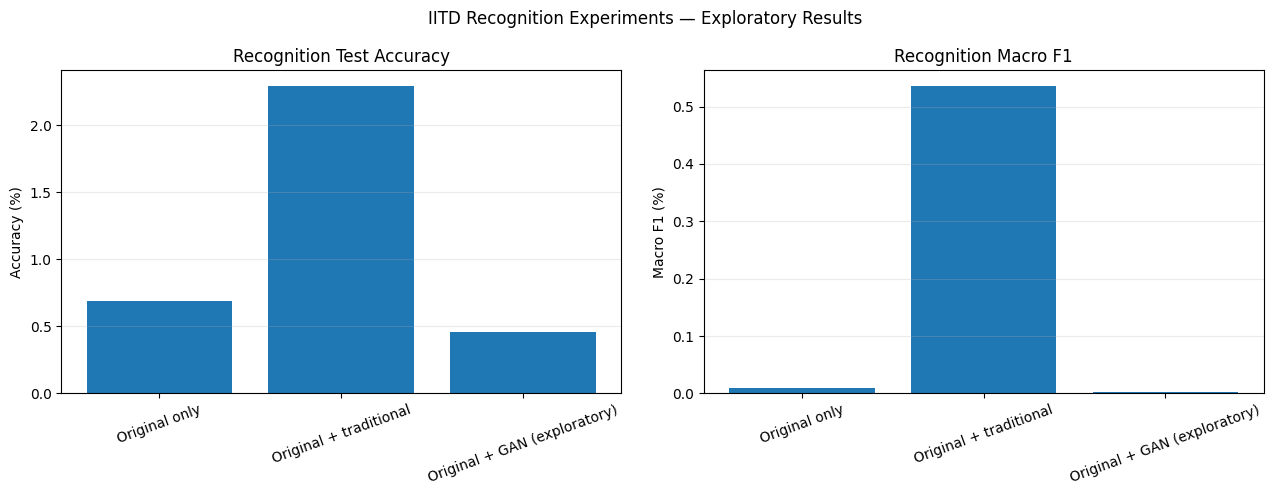

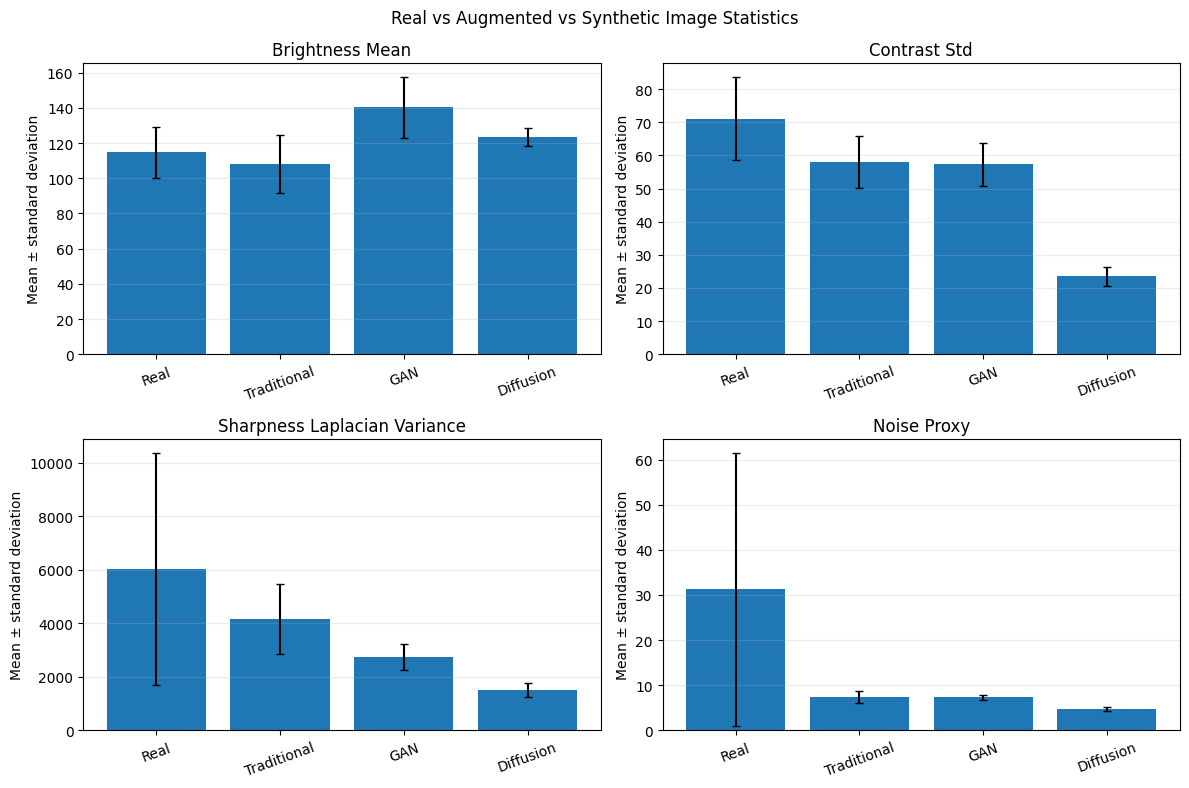

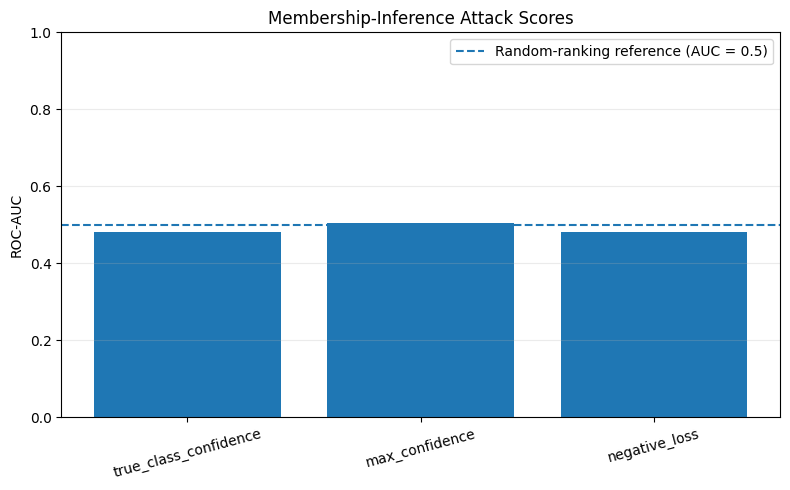


NOTEBOOK 14 OUTPUT VERIFICATION
OK | IITD_recognition_comparison.png | 70,374 bytes
OK | IITD_image_statistics_comparison.png | 113,675 bytes
OK | IITD_membership_attack_auc_comparison.png | 51,877 bytes
OK | IITD_final_recognition_summary.csv | 581 bytes
OK | IITD_final_membership_attack_summary.csv | 200 bytes
OK | IITD_notebook14_consolidated_summary.json | 1,129 bytes
OK | IITD_notebook14_findings.md | 1,047 bytes

JSON valid. No model training performed.


In [2]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ---------------------------------------------------------
# 1. Locate existing results
# ---------------------------------------------------------
N10 = RESULTS / "notebook10_recognition_augmented"
N11 = RESULTS / "notebook11_gan_vs_diffusion"
N12 = RESULTS / "notebook12_membership_inference"

recognition_path = N10 / "IITD_recognition_augmented_comparison.csv"
quality_path = N11 / "IITD_GAN_vs_Diffusion_metric_comparison.csv"
attack_path = N12 / "IITD_membership_attack_metrics.csv"

for p in [recognition_path, quality_path, attack_path]:
    assert p.is_file(), f"Required result missing: {p}"

recognition = pd.read_csv(recognition_path)
quality = pd.read_csv(quality_path)
attack = pd.read_csv(attack_path)

print("Loaded recognition experiments:", len(recognition))
print("Loaded image-statistic comparisons:", len(quality))
print("Loaded membership attack scores:", len(attack))

# ---------------------------------------------------------
# 2. Recognition accuracy and macro-F1 plots
# ---------------------------------------------------------
labels = recognition["experiment"].replace({
    "original_only": "Original only",
    "original_plus_traditional": "Original + traditional",
    "original_plus_GAN_exploratory": "Original + GAN (exploratory)"
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(labels, recognition["test_accuracy"] * 100)
axes[0].set_title("Recognition Test Accuracy")
axes[0].set_ylabel("Accuracy (%)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.25)

axes[1].bar(labels, recognition["test_macro_f1"] * 100)
axes[1].set_title("Recognition Macro F1")
axes[1].set_ylabel("Macro F1 (%)")
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(axis="y", alpha=0.25)

fig.suptitle("IITD Recognition Experiments — Exploratory Results")
fig.tight_layout()
recognition_png = OUT_DIR / "IITD_recognition_comparison.png"
fig.savefig(recognition_png, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---------------------------------------------------------
# 3. Real, traditional, GAN and diffusion statistics
# ---------------------------------------------------------
metric_names = [
    "brightness_mean",
    "contrast_std",
    "sharpness_laplacian_variance",
    "noise_proxy"
]

quality["dataset"] = quality["dataset"].replace({
    "Real images": "Real",
    "Traditional augmentation": "Traditional",
    "GAN": "GAN",
    "Diffusion": "Diffusion"
})

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, metric in zip(axes.ravel(), metric_names):
    subset = quality[quality["metric"] == metric]
    ax.bar(subset["dataset"], subset["mean"],
           yerr=subset["std"], capsize=3)
    ax.set_title(metric.replace("_", " ").title())
    ax.set_ylabel("Mean ± standard deviation")
    ax.tick_params(axis="x", rotation=20)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle("Real vs Augmented vs Synthetic Image Statistics")
fig.tight_layout()
quality_png = OUT_DIR / "IITD_image_statistics_comparison.png"
fig.savefig(quality_png, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---------------------------------------------------------
# 4. Membership inference ROC-AUC
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(attack["attack_score"], attack["roc_auc"])
ax.axhline(0.5, linestyle="--",
           label="Random-ranking reference (AUC = 0.5)")
ax.set_ylim(0, 1)
ax.set_ylabel("ROC-AUC")
ax.set_title("Membership-Inference Attack Scores")
ax.tick_params(axis="x", rotation=15)
ax.legend()
ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
attack_png = OUT_DIR / "IITD_membership_attack_auc_comparison.png"
fig.savefig(attack_png, dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

# ---------------------------------------------------------
# 5. Export compact tables and consolidated JSON
# ---------------------------------------------------------
recognition_cols = [
    "experiment", "training_images", "epochs",
    "best_validation_accuracy", "test_images", "test_accuracy",
    "test_macro_precision", "test_macro_recall", "test_macro_f1",
    "exploratory_unverified_identity_labels"
]
recognition_summary = recognition[recognition_cols].copy()
recognition_summary.to_csv(
    OUT_DIR / "IITD_final_recognition_summary.csv", index=False
)

attack_cols = [
    "attack_score", "roc_auc", "balanced_accuracy",
    "tpr_at_or_below_5pct_fpr"
]
attack_summary = attack[attack_cols].copy()
attack_summary.to_csv(
    OUT_DIR / "IITD_final_membership_attack_summary.csv", index=False
)

def metric_value(experiment, column):
    rows = recognition[recognition["experiment"] == experiment]
    return float(rows.iloc[0][column]) if not rows.empty else None

base_acc = metric_value("original_only", "test_accuracy")
trad_acc = metric_value("original_plus_traditional", "test_accuracy")
gan_acc = metric_value("original_plus_GAN_exploratory", "test_accuracy")

summary = {
    "notebook": "14_Result_Visualization_and_Ablation_Studies",
    "execution": {
        "cpu_only": True,
        "model_training_performed": False,
        "new_image_processing_performed": False
    },
    "recognition_test_accuracy": {
        "original_only": base_acc,
        "original_plus_traditional": trad_acc,
        "original_plus_GAN_exploratory": gan_acc
    },
    "membership_attack_roc_auc": {
        str(row["attack_score"]): float(row["roc_auc"])
        for _, row in attack.iterrows()
    },
    "limitations": [
        "These are exploratory comparisons, not a controlled ablation study.",
        "Notebook 10 experiments used two epochs and are not directly comparable to the earlier baseline run.",
        "GAN conditioning labels are not verified biometric identity labels.",
        "Low-level image statistics do not establish identity preservation or perceptual quality.",
        "Membership attack results near AUC 0.5 do not prove absence of privacy leakage."
    ],
    "figures": [
        recognition_png.name, quality_png.name, attack_png.name
    ]
}

json_path = OUT_DIR / "IITD_notebook14_consolidated_summary.json"
with open(json_path, "w") as f:
    json.dump(summary, f, indent=2)

report = f"""# Notebook 14 — Visualization and Ablation-Style Findings

## Recognition results

- Original-only test accuracy: {base_acc:.5f}
- Original + traditional augmentation: {trad_acc:.5f}
- Original + GAN (exploratory): {gan_acc:.5f}

Traditional augmentation has the highest recorded test accuracy among these three short Notebook 10 experiments. This is not proof of a reliable improvement because the experiments were not a matched-budget controlled ablation.

## Membership inference

The tested ROC-AUC values are close to 0.5 on the sampled data. This indicates little separation from the tested scores, not proof that privacy leakage is absent.

## Image statistics

Low-level brightness, contrast, sharpness and noise-proxy measurements differ across real, traditional, GAN and diffusion samples. They do not establish perceptual quality or biometric identity preservation. Sample counts differ.

## Limitations

No formal multi-seed, matched-compute ablation was conducted. GAN labels are not verified biometric identities. Recognition results are preliminary.
"""
(OUT_DIR / "IITD_notebook14_findings.md").write_text(report)

# ---------------------------------------------------------
# 6. Verify every output
# ---------------------------------------------------------
expected = [
    recognition_png,
    quality_png,
    attack_png,
    OUT_DIR / "IITD_final_recognition_summary.csv",
    OUT_DIR / "IITD_final_membership_attack_summary.csv",
    json_path,
    OUT_DIR / "IITD_notebook14_findings.md"
]

print("\nNOTEBOOK 14 OUTPUT VERIFICATION")
for p in expected:
    print(f"{'OK' if p.is_file() and p.stat().st_size > 0 else 'MISSING'}"
          f" | {p.name}"
          f" | {p.stat().st_size if p.is_file() else 0:,} bytes")

with open(json_path) as f:
    json.load(f)
print("\nJSON valid. No model training performed.")



# Final Conclusion — Result Visualization and Ablation Studies

## 1. Recognition Results

The three Notebook 10 experiments reported these test accuracies:

| Experiment | Test accuracy |
|---|---:|
| Original only | 0.69% |
| Original + traditional augmentation | 2.29% |
| Original + GAN (exploratory) | 0.46% |

Traditional augmentation achieved the highest recorded accuracy among these three experiments. However, these runs used only two epochs and were not a controlled ablation with matched training budgets. The results therefore do not establish a reliable improvement from augmentation.

## 2. Image Statistics

Brightness, contrast, sharpness, and the exploratory noise proxy differed between real images, traditional augmentation, GAN samples, and diffusion samples.

These low-level statistics alone cannot establish perceptual quality, biometric identity preservation, or suitability for recognition. Sample counts also differed across sources.

## 3. Membership-Inference Results

The tested membership-inference ROC-AUC values were approximately 0.480, 0.505, and 0.480.

These values are close to the random-ranking reference of 0.5, indicating little separation from the tested scores on the sampled data. This does not prove the absence of privacy leakage.

## 4. Ablation Study Limitations

This notebook consolidates existing experimental results rather than conducting a formal controlled ablation. The experiments did not use matched training budgets and repeated random seeds. GAN conditioning labels were not verified biometric identity labels.

## Overall Conclusion

This notebook provides a consolidated visualization of recognition performance, synthetic-image statistics, and membership-inference results. Traditional augmentation had the highest recorded recognition accuracy among the short Notebook 10 runs, but further controlled experiments are required before drawing definitive conclusions about augmentation benefits, generator quality, identity preservation, or privacy protection.

All figures and summary files were generated from previously saved results without additional model training.
